# Projeto Final - Entrega 3 (Modelo Avaliado)
## Meu Jogo É Baum?

---

**Machine Learning**

Tecnologia em Análise e Desenvolvimento de Sistemas

Instituto Federal de Mato Grosso do Sul - Câmpus Três Lagoas

Prof. Carlos R Santos Jr

**Integrantes:** Kenzo Senna, Hudson Batista Brandão, Matheus Felipe

---

## Preparação da base e função `limpar(df)`

Mesma leitura, mesmos filtros, mesma função `limpar(df)` e mesma divisão 80/20 (`random_state=42`, `stratify=y`) do `01_eda.ipynb`. O `assert` confere que treino e teste têm o mesmo tamanho da Entrega 2. O teste (`X_te`, `y_te`) só é usado a partir da seção 4.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, make_scorer, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

RANDOM_STATE = 42
CLASSES = ['baixa', 'media', 'alta']
CORES = ['#2a78d6', '#eb6834', '#1baf7a']

df = pd.read_csv('../data/games.csv.gz')
print('Tamanho original:', df.shape)

# Filtros da Entrega 1
datas_brutas = pd.to_datetime(df['Release date'], format='mixed', errors='coerce')
df = df[(df['Estimated owners'] != '0 - 0') & (df['Estimated owners'].notna()) & (datas_brutas < '2025-12-01')].copy()
print('Tamanho após filtros da E1:', df.shape)

Tamanho original: (125855, 40)


Tamanho após filtros da E1: (100292, 40)


In [2]:
def limpar(df):
    df = df.copy()
    df = df.drop_duplicates()

    colunas_remover = [
        'AppID', 'Name', 'About the game', 'Reviews', 'Header image',
        'Website', 'Support url', 'Support email', 'Metacritic url',
        'Notes', 'Developers', 'Publishers', 'Screenshots', 'Movies',
        'Full audio languages', 'Discount', 'DLC count',
        'Positive', 'Negative', 'Recommendations', 'Peak CCU',
        'User score', 'Metacritic score', 'Score rank',
        'Average playtime forever', 'Average playtime two weeks',
        'Median playtime forever', 'Median playtime two weeks'
    ]
    df = df.drop(columns=colunas_remover, errors='ignore')

    datas = pd.to_datetime(df['Release date'], format='mixed', errors='coerce')
    df['Release date'] = datas.dt.month

    df['Supported languages'] = df['Supported languages'].replace('[]', np.nan)
    df['Supported languages'] = df['Supported languages'].str.split(',').str.len()

    df['Genres'] = df['Genres'].str.split(',').str[0].str.strip()
    df['Categories'] = df['Categories'].str.split(',').str[0].str.strip()
    df['Tags'] = df['Tags'].str.split(',').str[0].str.strip()

    df['Windows'] = df['Windows'].astype(str)
    df['Mac'] = df['Mac'].astype(str)
    df['Linux'] = df['Linux'].astype(str)

    df.loc[(df['Price'] < 0) | (df['Price'] > 200), 'Price'] = np.nan
    df.loc[(df['Achievements'] < 0) | (df['Achievements'] > 500), 'Achievements'] = np.nan

    df['Required age'] = pd.cut(
        df['Required age'],
        bins=[-1, 0, 12, 15, 17, 100],
        labels=['Livre', '10+', '13+', '16+', '18+']
    ).astype(object)

    return df

df_limpo = limpar(df)

mapa_alvo = {
    '0 - 20000': 'baixa',
    '20000 - 50000': 'media',
    '50000 - 100000': 'media',
    '100000 - 200000': 'media'
}
y = df_limpo['Estimated owners'].map(lambda x: mapa_alvo.get(x, 'alta'))
X = df_limpo.drop(columns=['Estimated owners'])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

assert X_tr.shape == (80233, 11) and X_te.shape == (20059, 11), 'a divisão ficou diferente da usada no 01_eda'
print('Treino:', X_tr.shape, '| Teste:', X_te.shape)

Treino: (80233, 11) | Teste: (20059, 11)


## Pré-processador (`ColumnTransformer`)

Mesmo pré-processador da Entrega 2. Ele fica em uma função para que cada modelo receba uma cópia nova, e entra sempre dentro do `Pipeline`: em cada dobra da validação cruzada, a imputação, a escala e o encoding são aprendidos só com a parte de treino da dobra.

In [3]:
num_cols = ['Price', 'Achievements', 'Supported languages']
cat_cols = ['Genres', 'Tags', 'Categories', 'Release date', 'Windows', 'Mac', 'Linux']
ord_cols = ['Required age']
ordem = [['Livre', '10+', '13+', '16+', '18+']]

def criar_pre():
    num = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('esc', StandardScaler())
    ])
    cat = Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent', add_indicator=True)),
        ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=100, sparse_output=False))
    ])
    ordn = Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ord', OrdinalEncoder(categories=ordem, handle_unknown='use_encoded_value', unknown_value=-1))
    ])
    return ColumnTransformer([
        ('num', num, num_cols),
        ('cat', cat, cat_cols),
        ('ord', ordn, ord_cols)
    ], remainder='drop')

## 1. Qual é o número a bater?

As métricas foram definidas na Entrega 1: **F1-macro** (principal) e **precisão da classe `alta`** (secundária). A função `avaliar` roda validação cruzada de 5 dobras no treino e devolve a média de cada métrica e o desvio-padrão do F1-macro entre as dobras.

In [4]:
SCORING = {
    'f1_macro': 'f1_macro',
    'acuracia': 'accuracy',
    'precisao_alta': make_scorer(precision_score, labels=['alta'], average='macro', zero_division=0),
    'recall_alta': make_scorer(recall_score, labels=['alta'], average='macro', zero_division=0),
}

def avaliar(modelo, pesos=None):
    pipe = Pipeline([('pre', criar_pre()), ('modelo', modelo)])
    params = None if pesos is None else {'modelo__sample_weight': pesos}
    r = cross_validate(pipe, X_tr, y_tr, cv=5, scoring=SCORING, params=params)
    linha = {k: r[f'test_{k}'].mean() for k in SCORING}
    linha['f1_macro_dp'] = r['test_f1_macro'].std()
    return linha

base = avaliar(DummyClassifier(strategy='most_frequent'))
pd.DataFrame([base], index=['Dummy (most_frequent)']).round(4)

,f1_macro,acuracia,precisao_alta,recall_alta,f1_macro_dp
Dummy (most_frequent),0.2847,0.7452,0.0,0.0,0.0


**Observação:** O `DummyClassifier` responde sempre `baixa`. Ele acerta 74,52% dos jogos, mas o F1-macro fica em 0,2847 e a precisão da classe `alta` é zero, porque ele nunca prevê `media` nem `alta`.

**Decisão:** O número a bater é F1-macro = 0,2847, o mesmo da Entrega 1.

## 2. Qual algoritmo e qual peso para as classes?

Três algoritmos de famílias diferentes: regressão logística (linear), Random Forest (várias árvores independentes) e HistGradientBoosting (árvores em sequência, cada uma corrigindo a anterior).

A Entrega 2 deixou combinado testar `class_weight="balanced"`. Aqui cada algoritmo é avaliado com três pesos para as classes:

- **sem peso:** todo jogo vale 1;
- **moderado (1-2-3):** um jogo `media` vale 2 e um `alta` vale 3;
- **balanced:** peso inversamente proporcional à frequência da classe (um jogo `alta` vale cerca de 14 vezes um `baixa`).

Os pesos entram como `sample_weight` no treino. Assim os três algoritmos recebem exatamente os mesmos pesos.

In [5]:
algoritmos = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

pesos = {
    'sem peso': None,
    'moderado (1-2-3)': y_tr.map({'baixa': 1, 'media': 2, 'alta': 3}),
    'balanced': pd.Series(compute_sample_weight('balanced', y_tr), index=y_tr.index),
}

linhas = []
for nome_alg, modelo in algoritmos.items():
    for nome_peso, w in pesos.items():
        linhas.append({'algoritmo': nome_alg, 'pesos': nome_peso, **avaliar(modelo, w)})

comparacao = pd.DataFrame(linhas)
comparacao.round(4)

,algoritmo,pesos,f1_macro,acuracia,precisao_alta,recall_alta,f1_macro_dp
0,LogisticRegression,sem peso,0.4146,0.7545,0.5589,0.1750,0.0045
1,LogisticRegression,moderado (1-2-3),0.5010,0.7266,0.4155,0.2984,0.0050
2,LogisticRegression,balanced,0.4511,0.5582,0.1980,0.6510,0.0030
3,RandomForest,sem peso,0.4356,0.7608,0.6577,0.1946,0.0039
4,RandomForest,moderado (1-2-3),0.5344,0.7456,0.4903,0.3579,0.0044
5,RandomForest,balanced,0.4855,0.5895,0.2502,0.6556,0.0048
6,HistGradientBoosting,sem peso,0.4787,0.7632,0.5628,0.2912,0.0060
7,HistGradientBoosting,moderado (1-2-3),0.5421,0.7366,0.4579,0.4020,0.0019
8,HistGradientBoosting,balanced,0.4885,0.5920,0.2543,0.6470,0.0072


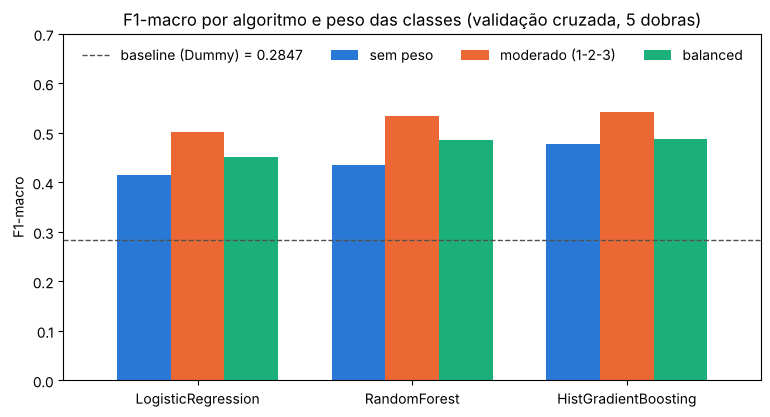

pesos,sem peso,moderado (1-2-3),balanced
algoritmo,,,
LogisticRegression,0.5589,0.4155,0.1980
RandomForest,0.6577,0.4903,0.2502
HistGradientBoosting,0.5628,0.4579,0.2543


In [6]:
tabela_f1 = comparacao.pivot(index='algoritmo', columns='pesos', values='f1_macro').loc[list(algoritmos), list(pesos)]

ax = tabela_f1.plot(kind='bar', color=CORES, figsize=(9, 4.5), width=0.75, rot=0)
ax.axhline(base['f1_macro'], color='#52514e', linestyle='--', linewidth=1, label=f"baseline (Dummy) = {base['f1_macro']:.4f}")
ax.set_title('F1-macro por algoritmo e peso das classes (validação cruzada, 5 dobras)')
ax.set_xlabel('')
ax.set_ylabel('F1-macro')
ax.set_ylim(0, 0.7)
ax.legend(ncol=4, loc='upper center', frameon=False)
plt.show()

comparacao.pivot(index='algoritmo', columns='pesos', values='precisao_alta').loc[list(algoritmos), list(pesos)].round(4)

**Observação:** Os três algoritmos superam o baseline em todas as combinações. Sem peso, os modelos quase não preveem `media` e `alta`: a precisão da classe `alta` é boa (0,56 a 0,66), mas o recall é baixo (0,18 a 0,29) e o F1-macro para entre 0,41 e 0,48. Com `balanced` acontece o contrário: o recall da `alta` sobe para 0,65, mas a precisão cai para 0,20 a 0,25, ou seja, de cada quatro jogos que o modelo chama de `alta`, pelo menos três não são. O peso moderado dá o melhor F1-macro nos três algoritmos e mantém a precisão da `alta` entre 0,42 e 0,49. O melhor resultado é o do HistGradientBoosting com peso moderado (F1-macro = 0,5421, desvio de 0,0019 entre dobras), à frente do Random Forest (0,5344) e da regressão logística (0,5010).

**Decisão:** Seguir com `HistGradientBoostingClassifier` e peso moderado (1-2-3). O `balanced` foi descartado porque piora justamente o erro que a Entrega 1 definiu como o mais caro: dizer `alta` para um jogo que não chega lá.

## 3. Vale ajustar os hiperparâmetros?

`GridSearchCV` com 5 dobras no treino, variando a taxa de aprendizado (`learning_rate`) e o tamanho máximo de cada árvore (`max_leaf_nodes`) do HistGradientBoosting. São 9 combinações, e o padrão do scikit-learn (`0.1` e `31`) é uma delas.

Regra definida antes de olhar o resultado: só trocamos o padrão se a melhor combinação ganhar dele por mais de um desvio-padrão entre dobras.

In [7]:
pesos_tr = pesos['moderado (1-2-3)']

pipe_hgb = Pipeline([
    ('pre', criar_pre()),
    ('modelo', HistGradientBoostingClassifier(random_state=RANDOM_STATE))
])
grade = {
    'modelo__learning_rate': [0.05, 0.1, 0.2],
    'modelo__max_leaf_nodes': [15, 31, 63],
}
busca = GridSearchCV(pipe_hgb, grade, scoring='f1_macro', cv=5)
busca.fit(X_tr, y_tr, modelo__sample_weight=pesos_tr)

res = pd.DataFrame(busca.cv_results_)[[
    'param_modelo__learning_rate', 'param_modelo__max_leaf_nodes', 'mean_test_score', 'std_test_score'
]]
res.columns = ['learning_rate', 'max_leaf_nodes', 'f1_macro', 'f1_macro_dp']
res.sort_values('f1_macro', ascending=False).round(4)

,learning_rate,max_leaf_nodes,f1_macro,f1_macro_dp
1,0.05,31,0.5426,0.0056
4,0.10,31,0.5421,0.0019
6,0.20,15,0.5400,0.0033
3,0.10,15,0.5397,0.0044
7,0.20,31,0.5397,0.0043
5,0.10,63,0.5394,0.0048
2,0.05,63,0.5393,0.0027
8,0.20,63,0.5373,0.0048
0,0.05,15,0.5356,0.0039


In [8]:
padrao = res[(res['learning_rate'] == 0.1) & (res['max_leaf_nodes'] == 31)].iloc[0]
melhor = res.loc[res['f1_macro'].idxmax()]
ganho = melhor['f1_macro'] - padrao['f1_macro']

if ganho > padrao['f1_macro_dp']:
    hiper = {'learning_rate': float(melhor['learning_rate']), 'max_leaf_nodes': int(melhor['max_leaf_nodes'])}
else:
    hiper = {'learning_rate': 0.1, 'max_leaf_nodes': 31}

print(f"Ganho do melhor da grade sobre o padrão: {ganho:.4f} (desvio entre dobras do padrão: {padrao['f1_macro_dp']:.4f})")
print('Hiperparâmetros escolhidos:', hiper)

Ganho do melhor da grade sobre o padrão: 0.0005 (desvio entre dobras do padrão: 0.0019)
Hiperparâmetros escolhidos: {'learning_rate': 0.1, 'max_leaf_nodes': 31}


**Observação:** As 9 combinações ficam entre 0,5356 e 0,5426 de F1-macro. A melhor (`learning_rate=0.05`, `max_leaf_nodes=31`) ganha do padrão por 0,0005, menos que o desvio de 0,0019 entre dobras. A diferença é ruído.

**Decisão:** Manter os hiperparâmetros padrão. O que limita o resultado são as informações disponíveis sobre o jogo, não o ajuste do algoritmo.

## 4. Como o modelo escolhido se sai no teste?

O pipeline final é treinado com todo o treino e avaliado em `X_te`, que não foi usado em nenhuma decisão até aqui. Esta é a única vez que o teste é aberto.

In [9]:
pipe_final = Pipeline([
    ('pre', criar_pre()),
    ('modelo', HistGradientBoostingClassifier(random_state=RANDOM_STATE, **hiper))
])
cv_final = avaliar(pipe_final['modelo'], pesos_tr)

pipe_final.fit(X_tr, y_tr, modelo__sample_weight=pesos_tr)
pred = pipe_final.predict(X_te)
proba = pipe_final.predict_proba(X_te)

dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)

def metricas(y_real, y_prev):
    return {
        'f1_macro': f1_score(y_real, y_prev, average='macro'),
        'acuracia': accuracy_score(y_real, y_prev),
        'precisao_alta': precision_score(y_real, y_prev, labels=['alta'], average='macro', zero_division=0),
        'recall_alta': recall_score(y_real, y_prev, labels=['alta'], average='macro', zero_division=0),
    }

teste = metricas(y_te, pred)
resultado = pd.DataFrame({
    'Dummy (teste)': metricas(y_te, dummy.predict(X_te)),
    'Modelo final (validação cruzada no treino)': {k: cv_final[k] for k in SCORING},
    'Modelo final (teste)': teste,
}).T
resultado.round(4)

,f1_macro,acuracia,precisao_alta,recall_alta
Dummy (teste),0.2847,0.7452,0.0000,0.0000
Modelo final (validação cruzada no treino),0.5421,0.7366,0.4579,0.4020
Modelo final (teste),0.5554,0.7423,0.4786,0.4384


In [10]:
print(classification_report(y_te, pred, labels=CLASSES, digits=4))

              precision    recall  f1-score   support

       baixa     0.8285    0.8780    0.8525     14948
       media     0.4001    0.3206    0.3560      4039
        alta     0.4786    0.4384    0.4576      1072

    accuracy                         0.7423     20059
   macro avg     0.5691    0.5457    0.5554     20059
weighted avg     0.7236    0.7423    0.7314     20059



**Observação:** No teste, o modelo chega a F1-macro = 0,5554 contra 0,2847 do Dummy, quase o dobro. O resultado fica próximo do da validação cruzada (0,5421), então não há sinal de que o modelo decorou o treino. A acurácia é praticamente igual à do Dummy (0,7423 contra 0,7452), o que confirma a escolha da Entrega 1: acurácia não distingue um modelo útil de um que só responde `baixa`. A precisão da classe `alta` é 0,4786: de cada 100 jogos que o modelo chama de `alta`, 48 são. Por classe, o modelo é bom em `baixa` (F1 = 0,85) e fraco em `media` (F1 = 0,36).

**Decisão:** O modelo supera o baseline com folga e segue para a aplicação. A resposta precisa vir com as probabilidades e com um aviso, porque uma previsão de `alta` erra um pouco mais do que acerta.

## 5. Onde o modelo erra?

### 5.1 Matriz de confusão

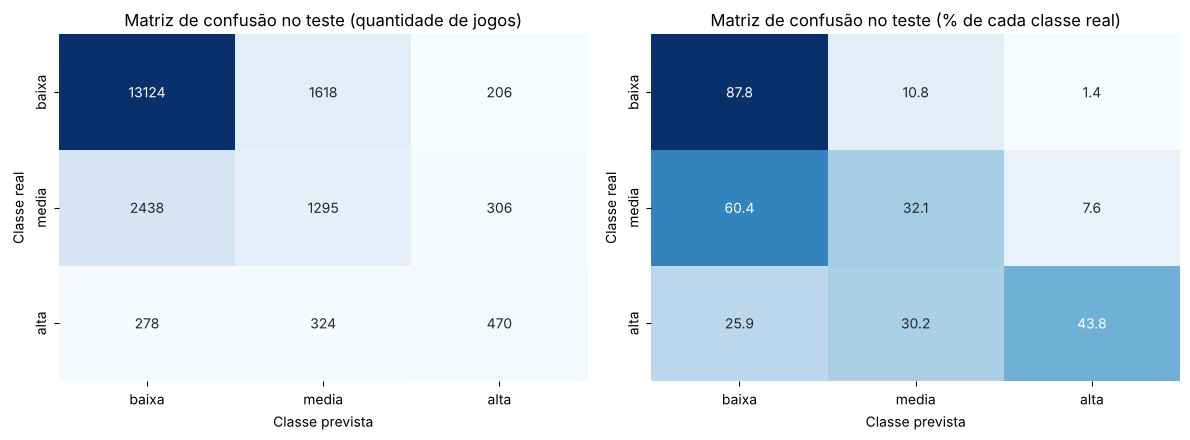

,real,previsto,jogos,% do teste
0,media,baixa,2438,12.15
1,baixa,media,1618,8.07
2,alta,media,324,1.62
3,media,alta,306,1.53
4,alta,baixa,278,1.39
5,baixa,alta,206,1.03


In [11]:
cm = confusion_matrix(y_te, pred, labels=CLASSES)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title('Matriz de confusão no teste (quantidade de jogos)')
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title('Matriz de confusão no teste (% de cada classe real)')
for ax in axes:
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
plt.tight_layout()
plt.show()

erros = pd.DataFrame({'real': y_te.values, 'previsto': pred})
erros = erros[erros['real'] != erros['previsto']]
tipos = erros.value_counts().rename('jogos').reset_index()
tipos['% do teste'] = (tipos['jogos'] / len(y_te) * 100).round(2)
tipos

**Observação:** O modelo erra 5.170 dos 20.059 jogos do teste (25,8%). Nove em cada dez erros (4.686) são entre faixas vizinhas, e o mais comum é chamar de `baixa` um jogo `media` (2.438 jogos, 60,4% da classe `media`). Os erros graves, entre `baixa` e `alta`, somam 484 jogos (2,4% do teste): 278 jogos `alta` previstos como `baixa` e 206 jogos `baixa` previstos como `alta`. Dos 982 jogos que o modelo chamou de `alta`, 470 são `alta`, 306 são `media` e 206 são `baixa`.

**Decisão:** A classe `media` é a mais difícil: o perfil desses jogos se confunde com o da `baixa`. Na interface, a resposta deve mostrar as três probabilidades em vez de só a classe, para o usuário ver quando o modelo ficou dividido entre duas faixas.

### 5.2 Jogos sem tag

A importância das colunas (seção 5.5) coloca `Tags` em primeiro lugar. Na Steam, as tags são votadas pelos jogadores depois do lançamento, então um jogo sem nenhuma tag é, na prática, um jogo que quase ninguém jogou.

In [12]:
sem_tag = X_te['Tags'].isna().values

linhas = []
for grupo, mascara in [('sem tag', sem_tag), ('com tag', ~sem_tag)]:
    linhas.append({
        'grupo': grupo,
        'jogos': int(mascara.sum()),
        '% real baixa': (y_te.values[mascara] == 'baixa').mean() * 100,
        '% previsto baixa': (pred[mascara] == 'baixa').mean() * 100,
        'acuracia': accuracy_score(y_te.values[mascara], pred[mascara]),
    })
print(pd.DataFrame(linhas).set_index('grupo').round(4).to_string())

pd.DataFrame({
    'Dummy (teste, só jogos com tag)': metricas(y_te.values[~sem_tag], dummy.predict(X_te[~sem_tag])),
    'Modelo final (teste, só jogos com tag)': metricas(y_te.values[~sem_tag], pred[~sem_tag]),
}).T.round(4)

         jogos  % real baixa  % previsto baixa  acuracia
grupo                                                   
sem tag   3398       99.9117           99.9706    0.9988
com tag  16661       69.3416           74.6834    0.6899


,f1_macro,acuracia,precisao_alta,recall_alta
"Dummy (teste, só jogos com tag)",0.2730,0.6934,0.0000,0.0000
"Modelo final (teste, só jogos com tag)",0.5417,0.6899,0.4791,0.4388


**Observação:** 3.398 jogos do teste (16,9%) não têm tag, e 99,9% deles são `baixa`. O modelo responde `baixa` para todos e acerta quase sempre, mas isso não é mérito: a falta de tag é uma consequência da baixa popularidade, não uma característica que o desenvolvedor informa. Quem preenche o formulário sempre escolhe uma tag, então o grupo que representa o uso real é o dos jogos com tag. Nesse grupo o F1-macro é 0,5417 (Dummy: 0,2730) e a acurácia cai para 0,6899.

**Decisão:** O modelo continua bem acima do baseline nos jogos com tag, então a conclusão da seção 4 se mantém. Para a aplicação, a taxa de acerto que vale é a do grupo com tag (69%), não a geral (74%). Na API, a tag será um campo obrigatório. Fica como ajuste para a próxima iteração tirar do treino os jogos sem tag.

### 5.3 Ano de lançamento

O alvo é o total de donos acumulado até a coleta do dataset. O formulário não tem o ano de lançamento (só o mês), então o modelo não sabe há quanto tempo o jogo está à venda.

Lançamentos por mês no arquivo original, a partir de out/2025:
Release date
2025-10    2564
2025-11    2410
2025-12    1909
2026-01    1565
2026-02    1706
2026-03      42
2026-06       1
2026-09       1
2026-12       1
Freq: M


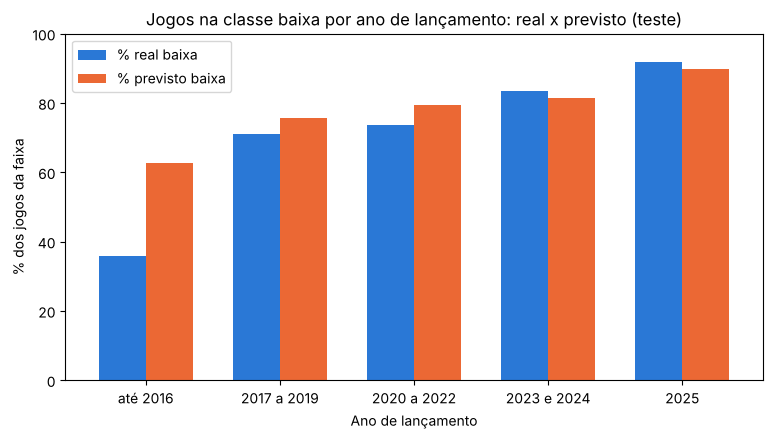

,jogos,% real baixa,% previsto baixa,% sem tag,acuracia,f1_macro
lançamento,,,,,,
até 2016,2023,35.937,62.580,0.840,0.523,0.508
2017 a 2019,4116,71.113,75.680,4.033,0.730,0.575
2020 a 2022,5664,73.499,79.467,10.946,0.725,0.548
2023 e 2024,5415,83.546,81.367,17.821,0.778,0.509
2025,2841,91.763,89.828,57.374,0.881,0.526


In [13]:
print('Lançamentos por mês no arquivo original, a partir de out/2025:')
print(datas_brutas[datas_brutas >= '2025-10-01'].dt.to_period('M').value_counts().sort_index().to_string())

ano = pd.to_datetime(df.loc[X_te.index, 'Release date'], format='mixed', errors='coerce').dt.year
faixa_ano = pd.cut(ano, bins=[0, 2016, 2019, 2022, 2024, 2025],
                   labels=['até 2016', '2017 a 2019', '2020 a 2022', '2023 e 2024', '2025'])
analise = pd.DataFrame({'faixa': faixa_ano.values, 'real': y_te.values, 'previsto': pred, 'sem_tag': sem_tag})

linhas = []
for faixa, g in analise.groupby('faixa', observed=True):
    linhas.append({
        'lançamento': faixa,
        'jogos': len(g),
        '% real baixa': (g['real'] == 'baixa').mean() * 100,
        '% previsto baixa': (g['previsto'] == 'baixa').mean() * 100,
        '% sem tag': g['sem_tag'].mean() * 100,
        'acuracia': accuracy_score(g['real'], g['previsto']),
        'f1_macro': f1_score(g['real'], g['previsto'], average='macro', labels=CLASSES, zero_division=0),
    })
por_ano = pd.DataFrame(linhas).set_index('lançamento')

ax = por_ano[['% real baixa', '% previsto baixa']].plot(kind='bar', color=CORES[:2], figsize=(9, 4.5), width=0.7, rot=0)
ax.set_title('Jogos na classe baixa por ano de lançamento: real x previsto (teste)')
ax.set_xlabel('Ano de lançamento')
ax.set_ylabel('% dos jogos da faixa')
ax.set_ylim(0, 100)
ax.legend(loc='upper left')
plt.show()

por_ano.round(3)

**Observação:** Entre os jogos lançados até 2016, só 35,9% são `baixa`, mas o modelo prevê `baixa` para 62,6%: ele subestima jogos antigos, que tiveram dez anos ou mais para acumular donos, e a acurácia nessa faixa cai para 0,52. Nos jogos de 2025 acontece o oposto: 91,8% são `baixa`, em boa parte porque ainda são recentes (57,4% deles nem têm tag). A contagem por mês mostra que a coleta do dataset foi até março de 2026. O filtro da Entrega 1 corta só os lançamentos a partir de dezembro de 2025, ou seja, cerca de três meses, e não os doze que a proposta descreve.

**Decisão:** Manter o filtro e a divisão da Entrega 2 nesta entrega, porque o teste já estava separado com eles. Fica registrado como limitação e como primeiro ajuste da próxima iteração: cortar os lançamentos a partir de março de 2025 e refazer a EDA e a modelagem.

### 5.4 A confiança do modelo é confiável?

A API vai devolver a classe prevista e a probabilidade de cada faixa. A pergunta aqui é se uma probabilidade maior significa mesmo mais acerto.

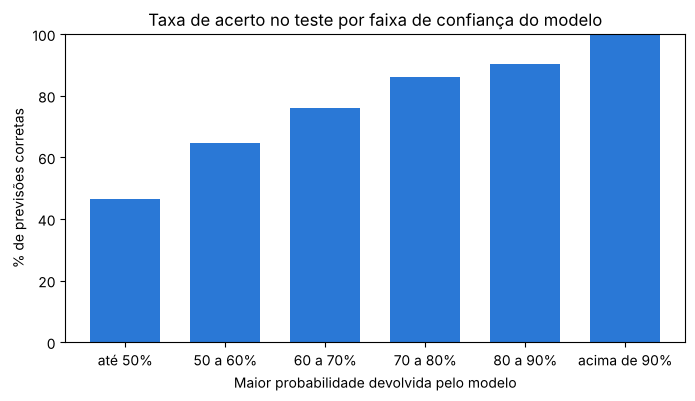

,jogos,acerto
confiança,,
até 50%,3701,46.4
50 a 60%,4893,64.5
60 a 70%,3739,76.0
70 a 80%,3276,86.1
80 a 90%,913,90.4
acima de 90%,3537,99.7


In [14]:
confianca = proba.max(axis=1)
faixa_conf = pd.cut(confianca, bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
                    labels=['até 50%', '50 a 60%', '60 a 70%', '70 a 80%', '80 a 90%', 'acima de 90%'])
conf = pd.DataFrame({'confiança': faixa_conf, 'acertou': pred == y_te.values})
tabela_conf = conf.groupby('confiança', observed=True)['acertou'].agg(jogos='size', acerto='mean')
tabela_conf['acerto'] = tabela_conf['acerto'] * 100

ax = tabela_conf['acerto'].plot(kind='bar', color=CORES[0], figsize=(8, 4), width=0.7, rot=0)
ax.set_title('Taxa de acerto no teste por faixa de confiança do modelo')
ax.set_xlabel('Maior probabilidade devolvida pelo modelo')
ax.set_ylabel('% de previsões corretas')
ax.set_ylim(0, 100)
plt.show()

tabela_conf.round(1)

**Observação:** A taxa de acerto cresce junto com a confiança: 46,4% quando a maior probabilidade é de até 50%, 76,0% entre 60 e 70% e 99,7% acima de 90%. A faixa acima de 90% (3.537 jogos) é formada quase toda pelos jogos sem tag da seção 5.2. Em 3.701 jogos (18,5% do teste) a maior probabilidade não passa de 50%, e nesses o modelo erra mais do que acerta.

**Decisão:** A resposta da aplicação vai mostrar a confiança e, quando ela for de até 50%, avisar que o modelo ficou dividido entre duas faixas.

### 5.5 O que mais pesa na previsão?

Importância por permutação: cada coluna é embaralhada no teste, uma por vez, e medimos quanto o F1-macro cai.

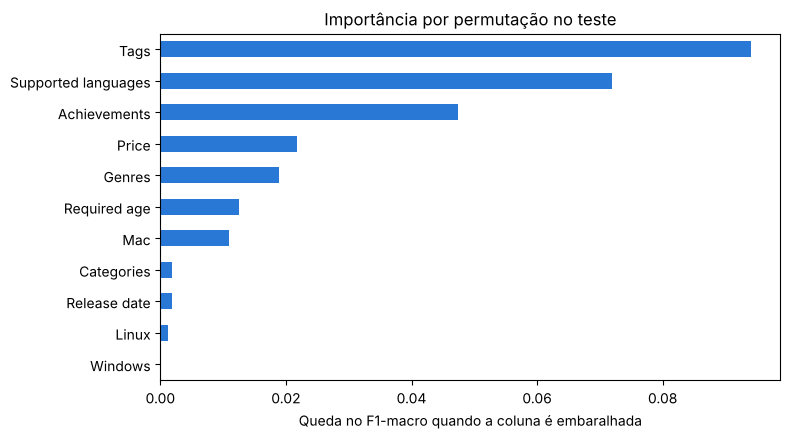

Tags                   0.0940
Supported languages    0.0720
Achievements           0.0474
Price                  0.0218
Genres                 0.0189
Required age           0.0126
Mac                    0.0110
Categories             0.0019
Release date           0.0019
Linux                  0.0012
Windows                0.0000
dtype: float64

In [15]:
imp = permutation_importance(pipe_final, X_te, y_te, scoring='f1_macro', n_repeats=5, random_state=RANDOM_STATE)
importancia = pd.Series(imp.importances_mean, index=X_te.columns).sort_values()

ax = importancia.plot(kind='barh', color=CORES[0], figsize=(8, 4.5))
ax.set_title('Importância por permutação no teste')
ax.set_xlabel('Queda no F1-macro quando a coluna é embaralhada')
plt.show()

importancia.sort_values(ascending=False).round(4)

**Observação:** `Tags` (queda de 0,094), `Supported languages` (0,072) e `Achievements` (0,047) são as colunas que mais pesam. `Price`, `Genres`, `Required age` e `Mac` contribuem pouco, e `Categories`, `Release date`, `Linux` e `Windows` quase nada. Parte do peso de `Tags` vem do efeito da seção 5.2. Isso mostra associação, não causa: jogos maiores costumam ter mais idiomas e mais conquistas, e adicionar idiomas a um jogo não garante mais donos.

**Decisão:** Nenhuma coluna é removida: as que pesam pouco não atrapalham e todas já estão no formulário. Na interface, a resposta não deve sugerir que mudar um campo muda o resultado do jogo.

## 6. Pipeline salvo

O artefato é o `Pipeline` completo (pré-processador + modelo), salvo em `models/pipeline.joblib`. O arquivo `models/modelo_info.json` guarda o nome e a versão do modelo, as colunas de entrada, um exemplo de entrada, as métricas e as versões das bibliotecas usadas no treino.

In [16]:
pasta_modelos = Path('../models')
pasta_modelos.mkdir(exist_ok=True)

joblib.dump(pipe_final, pasta_modelos / 'pipeline.joblib')

exemplo = {
    'Release date': 10, 'Required age': 'Livre', 'Price': 14.99, 'Supported languages': 5,
    'Windows': 'True', 'Mac': 'False', 'Linux': 'False', 'Achievements': 30,
    'Categories': 'Single-player', 'Genres': 'Action', 'Tags': 'Indie',
}

info = {
    'modelo': 'mjeb-hgb',
    'versao': '1.0.0',
    'algoritmo': 'HistGradientBoostingClassifier',
    'hiperparametros': hiper,
    'pesos_das_classes': {'baixa': 1, 'media': 2, 'alta': 3},
    'classes': list(pipe_final.classes_),
    'colunas_entrada': list(X_tr.columns),
    'exemplo_entrada': exemplo,
    'linhas_treino': len(X_tr),
    'linhas_teste': len(X_te),
    'metricas_teste': {k: round(float(v), 4) for k, v in teste.items()},
    'baseline_teste': {k: round(float(v), 4) for k, v in resultado.loc['Dummy (teste)'].items()},
    'versoes': {'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'joblib': joblib.__version__},
}
(pasta_modelos / 'modelo_info.json').write_text(json.dumps(info, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

print('Arquivos salvos:', sorted(p.name for p in pasta_modelos.iterdir() if p.suffix in ('.joblib', '.json')))
print('Tamanho do pipeline:', round((pasta_modelos / 'pipeline.joblib').stat().st_size / 1024), 'KB')

Arquivos salvos: ['modelo_info.json', 'pipeline.joblib']
Tamanho do pipeline: 829 KB


In [17]:
carregado = joblib.load(pasta_modelos / 'pipeline.joblib')
assert (carregado.predict(X_te) == pred).all()

entrada = pd.DataFrame([exemplo])
print('Previsão:', carregado.predict(entrada)[0])
print('Probabilidades:', dict(zip(carregado.classes_, carregado.predict_proba(entrada)[0].round(3).tolist())))

Previsão: baixa
Probabilidades: {'alta': 0.118, 'baixa': 0.442, 'media': 0.441}


**Observação:** O pipeline carregado do arquivo devolve as mesmas previsões do pipeline em memória para todo o teste e responde a uma entrada nova, montada como um formulário. No exemplo, `baixa` e `media` ficam praticamente empatadas (44,2% e 44,1%), um caso em que a aplicação deve mostrar o aviso de baixa confiança.

**Decisão:** A API da Entrega 4 só precisa carregar `pipeline.joblib` com a mesma versão do scikit-learn (`1.9.1`, fixada no `requirements.txt`) e montar um `DataFrame` de uma linha com as 11 colunas, no formato que a `limpar(df)` produz.

## Resumo da Entrega 3

| Item | Resultado |
|---|---|
| Baseline | `DummyClassifier(most_frequent)`: F1-macro = 0,2847 |
| Algoritmos comparados | LogisticRegression, RandomForest e HistGradientBoosting, cada um com 3 pesos de classe |
| Validação | validação cruzada de 5 dobras no treino, com o pré-processamento dentro do `Pipeline` |
| Modelo escolhido | HistGradientBoosting, hiperparâmetros padrão, pesos 1-2-3 |
| Validação cruzada | F1-macro = 0,5421 (desvio de 0,0019); precisão `alta` = 0,4579 |
| Teste | F1-macro = 0,5554; precisão `alta` = 0,4786; recall `alta` = 0,4384 |
| Teste, só jogos com tag | F1-macro = 0,5417; acurácia = 0,6899 |
| Artefato | `models/pipeline.joblib` e `models/modelo_info.json` |

Limitações registradas para a próxima iteração: jogos sem tag no treino (5.2), filtro de lançamentos recentes mais curto que o descrito na proposta (5.3) e alvo que depende do tempo de mercado (5.3).